# PROG8431 – Problem Analysis Workshop C
## Transformations and Linear Regression on the Predictive Maintenance Dataset

| Name | Student ID |
|---|---|
| Davisen Veerasamy | 8899632 |
| Carlos Gutierrez | 9118309 |
| Nnamdi Ikengah | 9085175 |

**Dataset:** The AI4I 2020 Predictive Maintenance Dataset (10,000 runs of a milling machine), plus the product-type specifications
and failure rules published with the dataset, plus the operating-zone clusters from our Workshop B.

**GitHub Repository:** [https://github.com/DavisenV/Group1-PROG8431-ProblemAnalysis_Workshop_C.git]

**Contents**

1. Setup and Configuration
2. Load and Clean the Original Data
3. Add Data from Other Sources
4. Transform the Data (new variables)
5. Choose the Dependent Variable
6. Split into Training and Test Sets
7. Correlations
8. Simple Linear Regression (two models)
9. Multiple Linear Regression
10. Final Summary

## 1. Setup and Configuration

Clone the repository using the above link:
```bash
git clone https://github.com/DavisenV/Group1-PROG8431-ProblemAnalysis_Workshop_C.git
```
Open a terminal and navigate to the root directory
```bash
cd ./"your path here"
```
Create a virtual environment and activate
```bash
python -m venv .venv
.\.venv\Scripts\Activate.ps1
```
Install all the required packages using the requirements.txt
```bash
python -m pip install -r requirements.txt
```
Then run each code block below in order.

### Coding Set Up

We start by clearing old plots, output and variables so the notebook runs from a clean state.

In [1]:
# Clear plots
import matplotlib.pyplot as plt
plt.close('all')

# Clear console
from IPython.display import clear_output
clear_output()

# Clean workspace
%reset -f

### Import Necessary Packages

These are the same packages used in the MLR demo, plus `KMeans` from Workshop B.

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import urllib.request
import zipfile

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp, chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.cluster import KMeans

import statsmodels.api as sm
import statsmodels.formula.api as smf

# Set up number displays
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", None)
np.set_printoptions(suppress=True)

## 2. Load and Clean the Original Data

Same steps as Workshops A and B, so all our notebooks use the same column names:

1. Download the dataset from UCI if it is not already in the `data` folder.
2. Rename the columns to simple snake_case names.
3. Check for missing values and duplicates.
4. Drop `udi` and `product_id` (ID numbers only).

In [3]:
# Define paths inside a 'data' directory
data_dir = "data"
os.makedirs(data_dir, exist_ok=True)

# UCI AI4I 2020 Predictive Maintenance dataset zip URL
dataset_url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
zip_path = os.path.join(data_dir, "predictive_maintenance.zip")
csv_path = os.path.join(data_dir, "predictive_maintenance.csv")

# Download and extract if not present
if not os.path.exists(csv_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(dataset_url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    os.replace(os.path.join(data_dir, "ai4i2020.csv"), csv_path)
    print(f"Dataset saved to: {csv_path}")

# Load raw dataset
df = pd.read_csv(csv_path)

# 1. Rename columns (same names as Workshops A and B)
df.columns = [
    'udi', 'product_id', 'type', 'air_temp', 'process_temp',
    'rotational_speed', 'torque', 'tool_wear', 'machine_failure',
    'tool_wear_failure', 'heat_dissipation_failure', 'power_failure',
    'overstrain_failure', 'random_failure'
]

# 2. Check missing values & duplicates
print("Missing Values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

# 3. Drop ID columns
df_clean = df.drop(columns=['udi', 'product_id']).copy()

print("\nShape:", df_clean.shape)
display(df_clean.head())

Missing Values: 0
Duplicates: 0

Shape: (10000, 12)


,type,air_temp,process_temp,rotational_speed,torque,tool_wear,machine_failure,tool_wear_failure,heat_dissipation_failure,power_failure,overstrain_failure,random_failure
0,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0
1,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0
2,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0
3,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0
4,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0


The original file gives us **12 usable variables** (1 categorical, 5 sensor readings, 6 failure columns).
The assignment needs **at least 25**, so the next two sections add data from other sources and create new variables.

## 3. Add Data from Other Sources

### Source 1: Product type specifications (from the dataset documentation)

The people who made the AI4I dataset published how each product quality type (L / M / H) behaves.
This is in the dataset description on the UCI Machine Learning Repository and in the paper that introduced the data
(Matzka, 2020, *Explainable Artificial Intelligence for Predictive Maintenance Applications*). We typed this information
into a small table, `data/product_type_specs.csv`:

| Column | Meaning |
|---|---|
| `quality_label` | Low / Medium / High |
| `quality_rank` | 1 / 2 / 3 – an ordered number for the quality level |
| `tool_wear_added_min` | Minutes of tool wear each process adds (L = 2, M = 3, H = 5) |
| `osf_threshold_minNm` | The overstrain limit: if *tool wear × torque* goes above this, the tool fails (L = 11,000, M = 12,000, H = 13,000) |

**Why this source?** It is the official description of how the machine works, so it is the most reliable extra information
we can get for this data. It also lets us turn the product type into real numbers (like the overstrain limit), not just a letter.

We **merge** it onto our data using the `type` column (a left join, so every one of the 10,000 runs keeps its row).

In [4]:
specs = pd.read_csv("data/product_type_specs.csv")
display(specs)

# Merge on product type (left join keeps all 10,000 runs)
df_clean = df_clean.merge(
    specs.drop(columns=["source"]),
    on="type",
    how="left"
)

print("Shape after merge:", df_clean.shape)
print("Missing values after merge:", df_clean.isnull().sum().sum())
display(df_clean.head())

,type,quality_label,quality_rank,tool_wear_added_min,osf_threshold_minNm,source
0,L,Low,1,2,11000,AI4I 2020 dataset description (UCI ML Reposito...
1,M,Medium,2,3,12000,AI4I 2020 dataset description (UCI ML Reposito...
2,H,High,3,5,13000,AI4I 2020 dataset description (UCI ML Reposito...


Shape after merge: (10000, 16)
Missing values after merge: 0


,type,air_temp,process_temp,rotational_speed,torque,tool_wear,machine_failure,tool_wear_failure,heat_dissipation_failure,power_failure,overstrain_failure,random_failure,quality_label,quality_rank,tool_wear_added_min,osf_threshold_minNm
0,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0,Medium,2,3,12000
1,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0,Low,1,2,11000
2,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0,Low,1,2,11000
3,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0,Low,1,2,11000
4,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0,Low,1,2,11000


### Source 2: Failure rules (from the dataset documentation)

The same documentation explains the exact rule behind each failure type:

| Failure | Rule from the documentation |
|---|---|
| Heat dissipation (HDF) | process temp − air temp **< 8.6 K** *and* rotational speed **< 1380 rpm** |
| Power (PWF) | power (torque × speed in rad/s) **< 3,500 W** or **> 9,000 W** |
| Overstrain (OSF) | tool wear × torque **>** the limit for the product type (11,000 / 12,000 / 13,000 minNm) |
| Tool wear (TWF) | the tool fails or is replaced somewhere between **200 and 240 minutes** of wear |
| Random (RNF) | 0.1% chance on any run |

We save these numbers as constants. Before using them, we **check that they really match our data** – if they recreate
the failure flags exactly, we know the source is trustworthy.

In [5]:
# Failure rule thresholds from the dataset documentation
HDF_TEMP_DIFF_MAX = 8.6     # K
HDF_SPEED_MAX = 1380        # rpm
PWF_POWER_MIN = 3500        # W
PWF_POWER_MAX = 9000        # W
TWF_WEAR_MIN = 200          # min

# Quick check: do the rules recreate the failure flags in our data?
temp_diff_check = df_clean["process_temp"] - df_clean["air_temp"]
power_check = df_clean["torque"] * df_clean["rotational_speed"] * 2 * np.pi / 60
strain_check = df_clean["tool_wear"] * df_clean["torque"]

hdf_rule = (temp_diff_check < HDF_TEMP_DIFF_MAX) & (df_clean["rotational_speed"] < HDF_SPEED_MAX)
pwf_rule = (power_check < PWF_POWER_MIN) | (power_check > PWF_POWER_MAX)
osf_rule = strain_check > df_clean["osf_threshold_minNm"]

print("HDF rule matches the flag on", (hdf_rule == df_clean["heat_dissipation_failure"]).sum(), "of 10,000 runs")
print("PWF rule matches the flag on", (pwf_rule == df_clean["power_failure"]).sum(), "of 10,000 runs")
print("OSF rule matches the flag on", (osf_rule == df_clean["overstrain_failure"]).sum(), "of 10,000 runs")

HDF rule matches the flag on 10000 of 10,000 runs
PWF rule matches the flag on 10000 of 10,000 runs
OSF rule matches the flag on 10000 of 10,000 runs


All three rules match **10,000 out of 10,000** runs, so the documented values are correct for our data and we can safely use
them to build new variables. (We also checked every number in our specs table against the dataset page on the UCI website.)

### Source 3 (separate datasets): Ontario weather and electricity data

The AI4I data only describes the machine itself. A real plant also has **outside conditions** – the weather and the cost of
electricity – that a maintenance team would care about. We add three real public datasets:

| Dataset | Publisher | What we use | Link |
|---|---|---|---|
| Hourly weather, station KITCHENER/WATERLOO (Climate ID 6144239) | Environment and Climate Change Canada | outdoor temperature, dew point, humidity, precipitation, wind speed, station pressure | climate.weather.gc.ca |
| Hourly Ontario Energy Price (HOEP) | IESO (Independent Electricity System Operator) | wholesale electricity price ($/MWh) | reports-public.ieso.ca |
| Hourly Ontario Demand | IESO | total Ontario electricity demand (MW) | reports-public.ieso.ca |

**Why these sources?** They are official government / grid-operator data, free and hourly. Kitchener-Waterloo is a large
manufacturing area close to Conestoga College, so it is a realistic location for our milling machine. Electricity price matters
because the machine runs on power, and with a price we can estimate the **energy cost of each run**.

**The key assumption – how we join them:** AI4I has no date or time column, so there is no shared key. We make one stated assumption:

> **The 10,000 runs are in time order (by `udi`), one run per hour, starting 2024-01-01 00:00 (Eastern Standard Time).**

This is reasonable because the UCI documentation says air temperature was generated as a *random walk*, which is a time series,
so the row order is meant to be time order. With one run per hour the data covers **2024-01-01 to 2025-02-20**. Both Environment
Canada and IESO report in Eastern Standard Time (no daylight saving), so the hours line up exactly.

The files are downloaded the first time the notebook runs and saved in `data/external/`, so later runs work offline.

In [6]:
ext_dir = os.path.join("data", "external")
os.makedirs(ext_dir, exist_ok=True)

weather_path = os.path.join(ext_dir, "weather_kitchener_waterloo_hourly.csv")
price_path = os.path.join(ext_dir, "ieso_hoep_hourly.csv")
demand_path = os.path.join(ext_dir, "ieso_ontario_demand_hourly.csv")

# 1. Environment Canada hourly weather (one file per month)
if not os.path.exists(weather_path):
    print("Downloading Environment Canada weather...")
    months = pd.date_range("2024-01-01", "2025-02-01", freq="MS")
    frames = []
    for m in months:
        url = ("https://climate.weather.gc.ca/climate_data/bulk_data_e.html?format=csv"
               f"&stationID=48569&Year={m.year}&Month={m.month}&Day=1&timeframe=1&submit=Download+Data")
        frames.append(pd.read_csv(url, encoding="utf-8-sig"))
    pd.concat(frames).to_csv(weather_path, index=False)

# 2. IESO hourly price (HOEP) and 3. IESO hourly Ontario demand (one file per year)
if not os.path.exists(price_path):
    print("Downloading IESO price data...")
    frames = [pd.read_csv(f"https://reports-public.ieso.ca/public/PriceHOEPPredispOR/PUB_PriceHOEPPredispOR_{y}.csv",
                          skiprows=3) for y in [2024, 2025]]
    pd.concat(frames).to_csv(price_path, index=False)

if not os.path.exists(demand_path):
    print("Downloading IESO demand data...")
    frames = [pd.read_csv(f"https://reports-public.ieso.ca/public/Demand/PUB_Demand_{y}.csv",
                          skiprows=3) for y in [2024, 2025]]
    pd.concat(frames).to_csv(demand_path, index=False)

weather_raw = pd.read_csv(weather_path)
price_raw = pd.read_csv(price_path)
demand_raw = pd.read_csv(demand_path)

print("Weather rows:", len(weather_raw), "| Price rows:", len(price_raw), "| Demand rows:", len(demand_raw))
print("Weather station:", weather_raw["Station Name"].unique())

Weather rows: 10200 | Price rows: 11664 | Demand rows: 17543
Weather station: <StringArray>
['KITCHENER/WATERLOO']
Length: 1, dtype: str


#### Clean the external data

- **Weather:** keep the useful columns and give them simple names. A few hours are missing (mostly wind speed). Because weather
  changes smoothly from hour to hour, we fill the gaps with **linear interpolation** (the average of the hours before and after).
  We drop wind direction and visibility (many gaps, and visibility is capped at 16.1 km).
- **IESO:** the files use "Hour 1 to 24" (hour ending). We change this to a normal timestamp, so Hour 1 on a day = 00:00.

In [7]:
# Weather: rename and keep useful columns
weather = weather_raw.rename(columns={
    "Date/Time (LST)": "timestamp",
    "Temp (°C)": "outdoor_temp_c",
    "Dew Point Temp (°C)": "dew_point_c",
    "Rel Hum (%)": "rel_humidity",
    "Precip. Amount (mm)": "precip_mm",
    "Wind Spd (km/h)": "wind_speed_kmh",
    "Stn Press (kPa)": "station_pressure_kpa"
})
weather_cols = ["outdoor_temp_c", "dew_point_c", "rel_humidity", "precip_mm", "wind_speed_kmh", "station_pressure_kpa"]
weather = weather[["timestamp"] + weather_cols]
weather["timestamp"] = pd.to_datetime(weather["timestamp"])

print("Missing weather values BEFORE filling:")
print(weather[weather_cols].isnull().sum())

# Fill small gaps using the hours before and after
weather[weather_cols] = weather[weather_cols].interpolate(method="linear", limit_direction="both")
print("\nMissing weather values AFTER filling:", weather[weather_cols].isnull().sum().sum())

# IESO: change "Hour 1-24" into a timestamp
price = price_raw[["Date", "Hour", "HOEP"]].copy()
price["timestamp"] = pd.to_datetime(price["Date"]) + pd.to_timedelta(price["Hour"] - 1, unit="h")
price = price[["timestamp", "HOEP"]].rename(columns={"HOEP": "hoep_price"})

demand = demand_raw[["Date", "Hour", "Ontario Demand"]].copy()
demand["timestamp"] = pd.to_datetime(demand["Date"]) + pd.to_timedelta(demand["Hour"] - 1, unit="h")
demand = demand[["timestamp", "Ontario Demand"]].rename(columns={"Ontario Demand": "ontario_demand_mw"})

print("\nMissing price values:", price["hoep_price"].isnull().sum(), "| Missing demand values:", demand["ontario_demand_mw"].isnull().sum())

Missing weather values BEFORE filling:
outdoor_temp_c           24
dew_point_c              33
rel_humidity             32
precip_mm                23
wind_speed_kmh          370
station_pressure_kpa     23
dtype: int64

Missing weather values AFTER filling: 0

Missing price values: 0 | Missing demand values: 0


#### Merge everything on the timestamp

In [8]:
# Our assumption: one run per hour, in udi order, starting 2024-01-01 00:00 (EST)
df_clean["timestamp"] = pd.date_range("2024-01-01 00:00", periods=len(df_clean), freq="h")
print("First run:", df_clean["timestamp"].min(), "| Last run:", df_clean["timestamp"].max())

# Left joins keep all 10,000 runs
df_clean = df_clean.merge(weather, on="timestamp", how="left")
df_clean = df_clean.merge(price, on="timestamp", how="left")
df_clean = df_clean.merge(demand, on="timestamp", how="left")

print("Shape after merge:", df_clean.shape)
print("Missing values after merge:", df_clean.isnull().sum().sum())
display(df_clean[["timestamp", "air_temp", "torque"] + weather_cols + ["hoep_price", "ontario_demand_mw"]].head())

First run: 2024-01-01 00:00:00 | Last run: 2025-02-20 15:00:00
Shape after merge: (10000, 25)
Missing values after merge: 0


,timestamp,air_temp,torque,outdoor_temp_c,dew_point_c,rel_humidity,precip_mm,wind_speed_kmh,station_pressure_kpa,hoep_price,ontario_demand_mw
0,2024-01-01 00:00:00,298.100,42.800,-1.300,-1.700,97.000,0.800,13.000,97.660,46.420,14482
1,2024-01-01 01:00:00,298.200,46.300,-1.600,-2.300,95.000,0.500,13.000,97.680,35.850,14180
2,2024-01-01 02:00:00,298.100,49.400,-1.800,-2.900,92.000,0.200,15.000,97.740,27.730,13722
3,2024-01-01 03:00:00,298.200,39.500,-1.900,-3.200,91.000,0.000,11.000,97.790,19.340,13637
4,2024-01-01 04:00:00,298.200,40.000,-2.100,-3.500,90.000,0.000,9.000,97.800,20.230,13697


Every one of the 10,000 runs found a matching hour in all three datasets (no missing values after the merge).

**Sanity check on our assumption:** if AI4I really came from a real plant in our timeline, its `air_temp` (the temperature
inside the plant) might follow the outdoor temperature a little. Let's look.

Correlation between AI4I air_temp and real outdoor temperature: 0.774


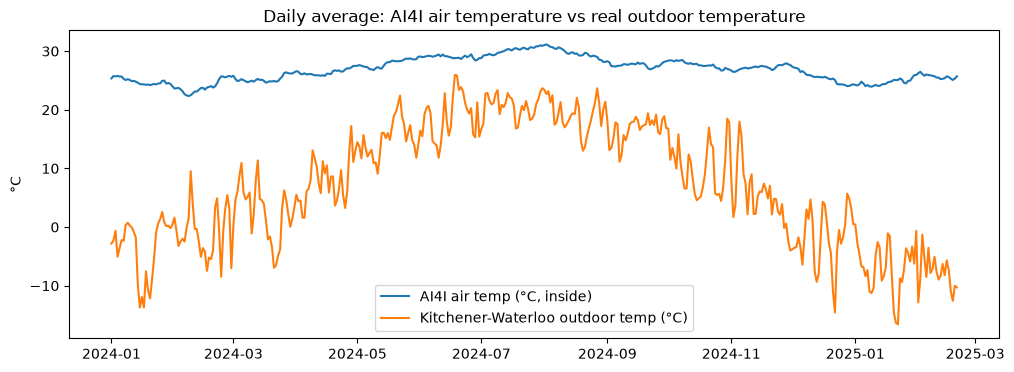

Correlation of day-to-day CHANGES: 0.002


In [9]:
print("Correlation between AI4I air_temp and real outdoor temperature:",
      round(df_clean["air_temp"].corr(df_clean["outdoor_temp_c"]), 3))

fig, ax1 = plt.subplots(figsize=(12, 4))
daily = df_clean.set_index("timestamp")[["air_temp", "outdoor_temp_c"]].resample("D").mean()
ax1.plot(daily.index, daily["air_temp"] - 273.15, label="AI4I air temp (°C, inside)")
ax1.plot(daily.index, daily["outdoor_temp_c"], label="Kitchener-Waterloo outdoor temp (°C)")
ax1.set_title("Daily average: AI4I air temperature vs real outdoor temperature")
ax1.set_ylabel("°C")
ax1.legend()
plt.show()

# Do the day-to-day CHANGES match as well?
daily_change = daily.diff().dropna()
print("Correlation of day-to-day CHANGES:",
      round(daily_change["air_temp"].corr(daily_change["outdoor_temp_c"]), 3))

**What we found – and why we have to be careful:**

- The correlation is about **0.77**, which looks strong. In the chart, AI4I's air temperature rises to a peak in the middle of the
  file and drops again, and in our timeline that middle falls in **summer**. So the overall shape fits a plant that gets warmer
  inside during summer, which supports our timeline.
- **But** the correlation of the **day-to-day changes** is about **0**. On a cold snap or heat wave outside, AI4I's temperature does
  not react at all. The match is only in the overall shape, not in the details.
- This is a classic trap with time data: **two series that both rise and fall slowly can look correlated by coincidence**
  (a *spurious correlation*). AI4I was generated by a simulation, not measured at a Kitchener plant, so we treat the 0.77 as a
  coincidence, not proof.
- **What it means for our models:** we expect the weather and electricity variables to have little or no real effect on torque.
  The regression in Section 9 will test this.

### Source 4: Operating-zone clusters from our Workshop B

In Workshop B we used K-Means on standardized rotational speed and torque (k = 4) and found four operating zones with very
different failure rates. We re-run the same clustering here (same settings) and add the zone as a new categorical variable.
The zone names are given by ordering the cluster centres from highest to lowest torque, so the names come out the same on
any computer.

In [10]:
# Same standardization and K-Means settings as Workshop B
def stamn(x):
    return (x - x.mean()) / x.std()

X_clust = pd.DataFrame({
    "speed_std": stamn(df_clean["rotational_speed"]),
    "torque_std": stamn(df_clean["torque"])
})

km = KMeans(n_clusters=4, max_iter=10, n_init=10, random_state=123)
km.fit(X_clust)

# Name the clusters by their torque centre (highest torque first)
torque_order = np.argsort(-km.cluster_centers_[:, 1])
zone_names = ["Slow & Heavy Load", "Normal Operation", "Moderate-Fast, Light Load", "Fast & Light Load"]
name_for_label = {label: zone_names[i] for i, label in enumerate(torque_order)}

df_clean["operating_zone"] = pd.Series(km.labels_).map(name_for_label)

print(df_clean["operating_zone"].value_counts())

operating_zone
Normal Operation             4161
Moderate-Fast, Light Load    2639
Slow & Heavy Load            2608
Fast & Light Load             592
Name: count, dtype: int64


The zone sizes (2,608 / 4,161 / 2,639 / 592) are the same as in Workshop B.

## 4. Transform the Data (new variables)

Now we use the extra information to create new variables. Each one has a reason:

| New variable | How it is made | Why |
|---|---|---|
| `temp_diff` | process_temp − air_temp | The heat-dissipation rule uses this difference |
| `power_w` | torque × speed × 2π / 60 | Power in watts; the power-failure rule uses it |
| `power_margin_w` | distance from power to the nearest safe limit (3,500 or 9,000 W) | Small or negative = close to a power failure |
| `strain_minNm` | tool_wear × torque | The overstrain rule uses this |
| `osf_margin_minNm` | osf_threshold − strain | How much "room" is left before an overstrain failure |
| `tool_uses` | tool_wear ÷ tool_wear_added_min | Roughly how many processes the tool has done |
| `log_speed` | log(rotational_speed) | Tukey's ladder (power 0) to reduce the skew in speed |
| `inv_speed` | 1000 ÷ rotational_speed | Tukey's ladder (power −1); physics says torque = power ÷ speed |
| `wear_stage` | tool_wear cut into New / Used / Old / End of life | Easier to read than minutes; End of life = 200+ min (the TWF zone) |
| `n_failure_modes` | sum of the 5 failure flags | Some runs fail in more than one way |
| `failure_type` | name of the failure mode (or "No Failure" / "Multiple") | One readable label instead of 5 columns |
| `hour`, `day_of_week`, `month` | taken from the timestamp | When the run happened |
| `is_weekend` | 1 = Saturday or Sunday | Weekend production may be different |
| `shift` | Day (07–15), Evening (15–23), Night (23–07) | Plants work in shifts; easier to use than 24 hours |
| `season` | Winter / Spring / Summer / Fall from the month | Groups the weather into seasons |
| `log_hoep` | log(1 + hoep_price) | Tukey's ladder (power 0): electricity price has huge spikes (very right-skewed) |
| `energy_kwh` | power_w × tool_wear_added_min ÷ 60 ÷ 1000 | Energy used by one process (assumes the cutting time = the minutes of tool wear it adds) |
| `energy_cost_cad` | energy_kwh × hoep_price ÷ 1000 | Electricity cost of one process in dollars (HOEP is $ per MWh) |

We also **convert all categorical variables** (`type`, `quality_label`, `wear_stage`, `failure_type`, `operating_zone`, `shift`, `season`)
to the `category` type, just like `Pension` in the MLR demo.

In [11]:
# Temperature difference
df_clean["temp_diff"] = df_clean["process_temp"] - df_clean["air_temp"]

# Power in watts (speed changed from rpm to rad/s)
df_clean["power_w"] = df_clean["torque"] * df_clean["rotational_speed"] * 2 * np.pi / 60

# Distance to the nearest power limit (negative = outside the safe range)
df_clean["power_margin_w"] = np.minimum(
    df_clean["power_w"] - PWF_POWER_MIN,
    PWF_POWER_MAX - df_clean["power_w"]
)

# Strain and room left before overstrain
df_clean["strain_minNm"] = df_clean["tool_wear"] * df_clean["torque"]
df_clean["osf_margin_minNm"] = df_clean["osf_threshold_minNm"] - df_clean["strain_minNm"]

# Approximate number of processes done by the tool
df_clean["tool_uses"] = df_clean["tool_wear"] / df_clean["tool_wear_added_min"]

# Tukey's ladder transformations of rotational speed
df_clean["log_speed"] = np.log(df_clean["rotational_speed"])
df_clean["inv_speed"] = 1000 / df_clean["rotational_speed"]

# Tool wear stage
df_clean["wear_stage"] = pd.cut(
    df_clean["tool_wear"],
    bins=[-1, 69, 139, TWF_WEAR_MIN - 1, 1000],
    labels=["New", "Used", "Old", "End of life"]
)

# Failure mode count and label
failure_flags = ["tool_wear_failure", "heat_dissipation_failure", "power_failure",
                 "overstrain_failure", "random_failure"]
flag_names = {
    "tool_wear_failure": "Tool Wear",
    "heat_dissipation_failure": "Heat Dissipation",
    "power_failure": "Power",
    "overstrain_failure": "Overstrain",
    "random_failure": "Random"
}

df_clean["n_failure_modes"] = df_clean[failure_flags].sum(axis=1)

def label_failure(row):
    if row["n_failure_modes"] == 0:
        return "No Failure"
    if row["n_failure_modes"] > 1:
        return "Multiple"
    for flag in failure_flags:
        if row[flag] == 1:
            return flag_names[flag]

df_clean["failure_type"] = df_clean.apply(label_failure, axis=1)

# Time variables from the timestamp
df_clean["hour"] = df_clean["timestamp"].dt.hour
df_clean["day_of_week"] = df_clean["timestamp"].dt.dayofweek      # 0 = Monday, 6 = Sunday
df_clean["month"] = df_clean["timestamp"].dt.month
df_clean["is_weekend"] = (df_clean["day_of_week"] >= 5).astype(int)

def get_shift(hour):
    if 7 <= hour < 15:
        return "Day"
    elif 15 <= hour < 23:
        return "Evening"
    else:
        return "Night"

df_clean["shift"] = df_clean["hour"].apply(get_shift)

season_map = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer",
              9: "Fall", 10: "Fall", 11: "Fall"}
df_clean["season"] = df_clean["month"].map(season_map)

# Tukey's ladder (log) for the skewed electricity price; +1 because some prices are 0
df_clean["log_hoep"] = np.log(1 + df_clean["hoep_price"])

# Energy and cost of one process
df_clean["energy_kwh"] = df_clean["power_w"] * df_clean["tool_wear_added_min"] / 60 / 1000
df_clean["energy_cost_cad"] = df_clean["energy_kwh"] * df_clean["hoep_price"] / 1000

# Convert categorical variables
for col in ["type", "quality_label", "wear_stage", "failure_type", "operating_zone", "shift", "season"]:
    df_clean[col] = df_clean[col].astype("category")

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 46 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   type                      10000 non-null  category      
 1   air_temp                  10000 non-null  float64       
 2   process_temp              10000 non-null  float64       
 3   rotational_speed          10000 non-null  int64         
 4   torque                    10000 non-null  float64       
 5   tool_wear                 10000 non-null  int64         
 6   machine_failure           10000 non-null  int64         
 7   tool_wear_failure         10000 non-null  int64         
 8   heat_dissipation_failure  10000 non-null  int64         
 9   power_failure             10000 non-null  int64         
 10  overstrain_failure        10000 non-null  int64         
 11  random_failure            10000 non-null  int64         
 12  quality_label             1000

C:\Users\Davisen\AppData\Local\Temp\ipykernel_15796\2698530866.py:57: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_clean["day_of_week"] = df_clean["timestamp"].dt.dayofweek      # 0 = Monday, 6 = Sunday


### Tukey's ladder: does transforming rotational speed help?

In our first assignment we found rotational speed is strongly **right-skewed** (skew ≈ 2.0). The lecture showed that Tukey's
ladder of powers can change the shape of a skewed variable. We compare the original, log (power 0) and reciprocal (power −1).

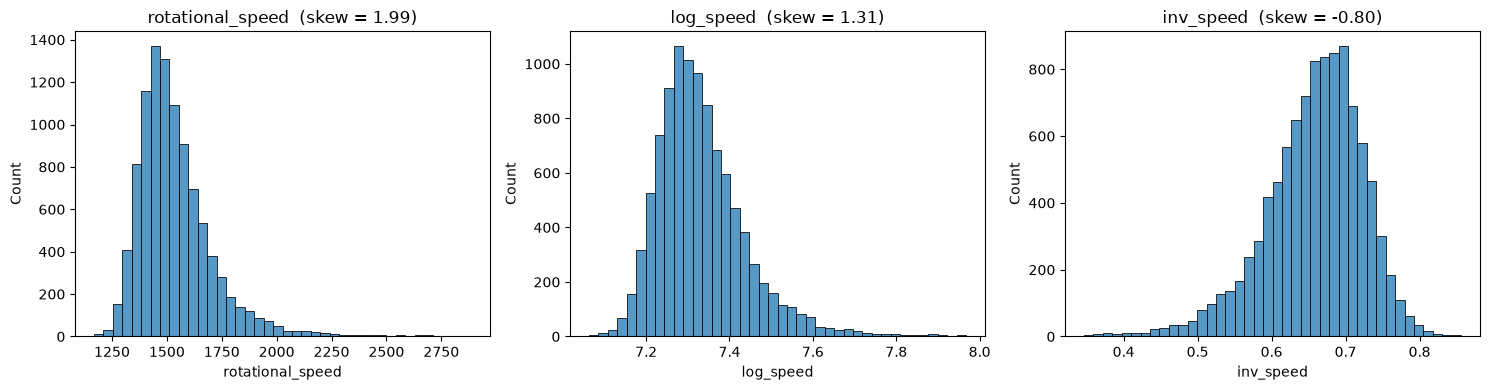

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["rotational_speed", "log_speed", "inv_speed"]):
    sns.histplot(df_clean[col], bins=40, ax=ax)
    ax.set_title(f"{col}  (skew = {df_clean[col].skew():.2f})")

plt.tight_layout()
plt.show()

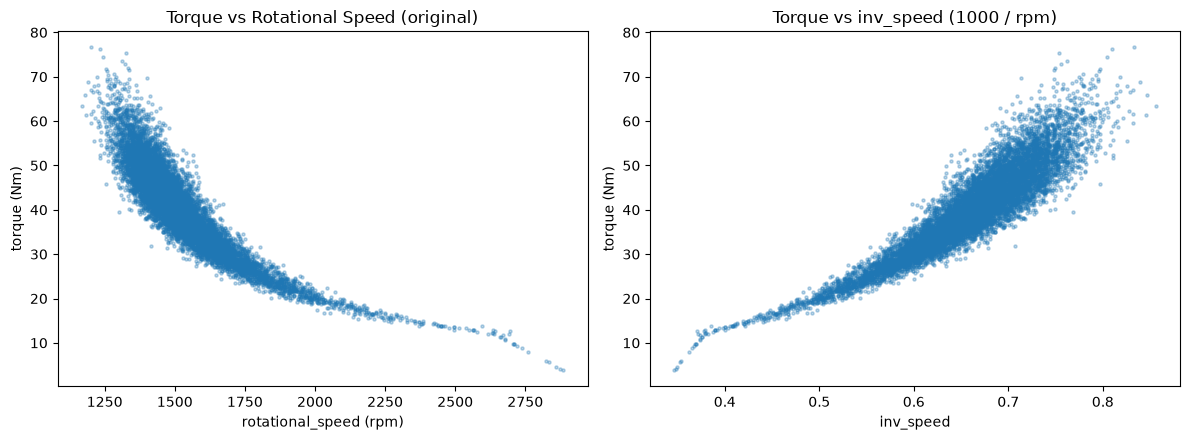

In [13]:
# How does torque relate to speed before and after the transformation?
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(df_clean["rotational_speed"], df_clean["torque"], s=5, alpha=0.3)
axes[0].set_title("Torque vs Rotational Speed (original)")
axes[0].set_xlabel("rotational_speed (rpm)")
axes[0].set_ylabel("torque (Nm)")

axes[1].scatter(df_clean["inv_speed"], df_clean["torque"], s=5, alpha=0.3)
axes[1].set_title("Torque vs inv_speed (1000 / rpm)")
axes[1].set_xlabel("inv_speed")
axes[1].set_ylabel("torque (Nm)")

plt.tight_layout()
plt.show()

**What we see:**

- **Skew:** the original speed has a skew of about **1.99**. The log brings it down to about **1.31**, and the reciprocal
  over-corrects a little to about **−0.80** (now slightly skewed the other way). As the lecture warned, the transformations do not make
  speed perfectly normal, but both reduce the skew.
- **Relationship with torque:** this is the bigger win. Against the original speed, the torque points form a **curve** (it bends and
  flattens out at high speed). Against `inv_speed` the points form a much **straighter line**. That makes sense from physics:
  power = torque × speed, so torque = power ÷ speed, and torque should be a straight line against 1 ÷ speed.
- Linear regression fits straight lines, so `inv_speed` should give a better model. We test this in Section 8.

The electricity price (HOEP) is also very skewed – most hours are cheap, but a few hours spike to over $1,000 per MWh.
We apply the same idea (log) to it.

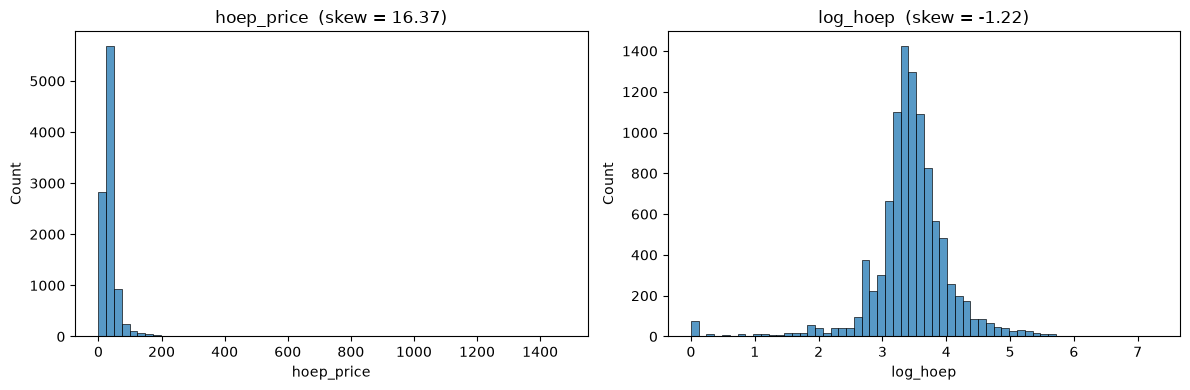

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean["hoep_price"], bins=60, ax=axes[0])
axes[0].set_title(f"hoep_price  (skew = {df_clean['hoep_price'].skew():.2f})")

sns.histplot(df_clean["log_hoep"], bins=60, ax=axes[1])
axes[1].set_title(f"log_hoep  (skew = {df_clean['log_hoep'].skew():.2f})")

plt.tight_layout()
plt.show()

**What we see:** the raw price has a skew of about **16.4** – most hours cost around $30 per MWh (median $30.15), but 68 hours are
above $200 and one reaches $1,476. After the log transformation the skew is about **−1.2**. It over-corrects a little, because 78 hours
had a price of exactly $0, but it is far less extreme, so a few spikes won't dominate a regression. We use `log_hoep` in the models.

**Energy cost:** with our energy variables, one process uses on average **0.27 kWh** and costs about **1 cent** at the wholesale price
(maximum about 80 cents during a price spike). Over all 10,000 runs that adds up to about **$101**.

### Final study file: variable count

In [15]:
# The timestamp is only used as a key to join the data, so we don't count it as a variable
print("Number of usable variables:", df_clean.shape[1] - 1, "(plus the timestamp key)")
print()

var_table = pd.DataFrame({
    "data_type": df_clean.dtypes.astype(str),
    "missing": df_clean.isnull().sum()
})
display(var_table)

# Save the final study file
df_clean.to_csv("data/study_file.csv", index=False)

Number of usable variables: 45 (plus the timestamp key)



,data_type,missing
type,category,0
air_temp,float64,0
process_temp,float64,0
rotational_speed,int64,0
torque,float64,0
tool_wear,int64,0
machine_failure,int64,0
tool_wear_failure,int64,0
heat_dissipation_failure,int64,0
power_failure,int64,0


**Data sources and transformations – summary**

- We started with **12 usable variables** from the AI4I dataset and now have **45**.
- **Sources added:** (1) product type specifications and (2) failure rules from the official dataset documentation,
  (3) three separate public datasets – Environment Canada hourly weather, IESO hourly electricity price and IESO hourly Ontario
  demand – joined on a timestamp, and (4) the operating-zone clusters from our Workshop B.
- **Why these sources:** the documentation describes exactly how the machine works (we proved this by recreating the HDF, PWF and
  OSF failure flags perfectly). The weather and electricity data add the real-world conditions around a plant, and let us estimate the
  energy cost of each run. The Workshop B zones carry forward our own earlier finding.
- **Main assumption:** one run per hour in `udi` order starting 2024-01-01. The sanity check showed AI4I's air temperature does not
  follow the real weather, so we expect the weather variables to have little effect on the machine readings.
- **Why these transformations:** most new variables are the physical quantities behind the failure rules (power, strain, margins),
  which are more meaningful than the raw readings. The log / reciprocal of speed are Tukey's ladder transformations for the skew and the
  curved relationship with torque. All categorical variables are converted to `category`.
- The final study file is saved as `data/study_file.csv`.

## 5. Choose the Dependent Variable

### Dependent variable: `torque` (Nm)

**Why torque?**

- In Workshop A and B torque was our **strongest warning sign**: failed runs had much higher torque (t-test), and the
  *Slow & Heavy Load* zone failed 10% of the time.
- Torque is **bell-shaped** (Shapiro-Wilk in Workshop A), which suits linear regression.
- **Business question:** *Can we estimate the expected torque (load) on the spindle from the other readings?* If the real torque
  is much higher than what the model expects, that is a sign something is wrong (anomaly detection, as described in the lecture).
  It could also act as a backup if the torque sensor fails.

**Important – variables we cannot use as predictors (data leakage):** some new variables are *calculated from torque*:
`power_w`, `power_margin_w`, `strain_minNm`, `osf_margin_minNm`, `energy_kwh`, `energy_cost_cad` and `operating_zone`. Using them to predict torque would be cheating,
because the answer is already hidden inside them. They stay in the study file for other parts of our term project, but are left out
of the regression models.

## 6. Split into Training and Test Sets

As in the class demo, we split the data **80% training / 20% test** with a fixed `random_state` so the split is the same every time.

- The **training set** (8,000 runs) is used to build the models.
- The **test set** (2,000 runs) is kept aside and only used to check how well the models work on data they have never seen.

80/20 is within the range from the lecture (training is typically 60–80%). Because we have 10,000 rows, 20% still gives a large
test set of 2,000 runs.

In [16]:
# Splitting with 80/20
train, test = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=6174
)

print("Train:", train.shape)
print("Test: ", test.shape)

Train: (8000, 46)
Test:  (2000, 46)


### Are the two sets comparable?

First we compare the summary statistics side by side.

In [17]:
compare_cols = ["air_temp", "process_temp", "rotational_speed", "torque", "tool_wear",
                "temp_diff", "inv_speed", "outdoor_temp_c", "rel_humidity", "hoep_price",
                "ontario_demand_mw", "machine_failure"]

summary_compare = pd.DataFrame({
    "train_mean": train[compare_cols].mean(),
    "test_mean": test[compare_cols].mean(),
    "train_std": train[compare_cols].std(),
    "test_std": test[compare_cols].std(),
    "train_min": train[compare_cols].min(),
    "test_min": test[compare_cols].min(),
    "train_max": train[compare_cols].max(),
    "test_max": test[compare_cols].max()
})

display(summary_compare)

,train_mean,test_mean,train_std,test_std,train_min,test_min,train_max,test_max
air_temp,300.017,299.957,2.002,1.993,295.300,295.300,304.500,304.300
process_temp,310.015,309.967,1.485,1.480,305.700,305.700,313.800,313.800
rotational_speed,1538.012,1541.834,178.740,181.457,1168.000,1192.000,2886.000,2874.000
torque,40.076,39.633,9.966,9.973,3.800,4.200,76.600,74.500
tool_wear,108.111,107.313,63.707,63.455,0.000,0.000,253.000,246.000
temp_diff,9.998,10.010,1.005,0.984,7.600,7.600,12.100,12.100
inv_speed,0.658,0.656,0.066,0.067,0.347,0.348,0.856,0.839
outdoor_temp_c,7.265,6.791,10.929,10.965,-21.100,-20.600,32.500,32.800
rel_humidity,78.707,79.486,16.862,16.154,22.000,29.000,100.000,100.000
hoep_price,37.143,36.728,41.887,31.550,0.000,0.000,1476.340,583.650


Then we use the **Kolmogorov-Smirnov (KS) test** for the numeric variables.

- H0: the training and test values come from the same distribution.
- If the p-value is **above 0.05**, we keep H0 and the sets are comparable for that variable.

In [18]:
# Comparing Numeric using Kolmogorov-Smirnov
numeric_vars = ["air_temp", "process_temp", "rotational_speed", "torque", "tool_wear",
                "temp_diff", "log_speed", "inv_speed", "tool_uses",
                "outdoor_temp_c", "dew_point_c", "rel_humidity", "precip_mm", "wind_speed_kmh",
                "station_pressure_kpa", "hoep_price", "log_hoep", "ontario_demand_mw", "energy_kwh"]

ks_rows = []
for var in numeric_vars:
    stat, p = ks_2samp(train[var], test[var])
    ks_rows.append({
        "Variable": var,
        "KS Statistic": round(stat, 4),
        "p-value": round(p, 4),
        "Same distribution?": "Yes" if p > 0.05 else "No"
    })

display(pd.DataFrame(ks_rows))

,Variable,KS Statistic,p-value,Same distribution?
0,air_temp,0.025,0.289,Yes
1,process_temp,0.021,0.447,Yes
2,rotational_speed,0.017,0.748,Yes
3,torque,0.022,0.425,Yes
4,tool_wear,0.015,0.833,Yes
5,temp_diff,0.016,0.811,Yes
6,log_speed,0.017,0.748,Yes
7,inv_speed,0.017,0.748,Yes
8,tool_uses,0.025,0.257,Yes
9,outdoor_temp_c,0.031,0.085,Yes


And the **Chi-square test** for the categorical variables.

- H0: the category proportions are the same in the training and test sets.

In [19]:
# Comparing Categorical with Chi-Square
cat_vars = ["type", "wear_stage", "operating_zone", "machine_failure", "failure_type",
            "shift", "season", "is_weekend"]

chi_rows = []
for var in cat_vars:
    trainp = train[var].value_counts().sort_index()
    testp = test[var].value_counts().sort_index()

    contingency_table = pd.DataFrame([trainp, testp], index=["Train", "Test"]).fillna(0)
    chi2, p, dof, expected = chi2_contingency(contingency_table)

    chi_rows.append({
        "Variable": var,
        "Chi-square": round(chi2, 4),
        "p-value": round(p, 4),
        "Same proportions?": "Yes" if p > 0.05 else "No"
    })

display(pd.DataFrame(chi_rows))

# Failure counts in each set
print("Failures in train:", train["machine_failure"].sum(), f"({train['machine_failure'].mean()*100:.2f}%)")
print("Failures in test: ", test["machine_failure"].sum(), f"({test['machine_failure'].mean()*100:.2f}%)")

,Variable,Chi-square,p-value,Same proportions?
0,type,1.271,0.530,Yes
1,wear_stage,1.913,0.591,Yes
2,operating_zone,2.662,0.447,Yes
3,machine_failure,0.261,0.609,Yes
4,failure_type,3.054,0.802,Yes
5,shift,1.936,0.380,Yes
6,season,5.024,0.170,Yes
7,is_weekend,1.504,0.220,Yes


Failures in train: 267 (3.34%)
Failures in test:  72 (3.60%)


**Results of the split:**

- The training set has **8,000 runs** and the test set has **2,000 runs** (80/20).
- The **means, standard deviations and min/max values are very close** for every variable. For example, average torque is 40.08 Nm in
  training and 39.63 Nm in test, and the standard deviations are almost identical (9.97 vs 9.97).
- **KS test:** all 19 numeric variables have p-values above 0.05, so we keep H0. Training and test come from the same distribution.
- **Chi-square test:** all 8 categorical variables (including `shift`, `season` and `is_weekend`) have p-values above 0.05, so the
  category proportions are the same.

**Small dissimilarities we noticed:**

- The test set has a slightly higher failure rate (**3.60%** vs **3.34%**, i.e. 72 vs 267 failures). The chi-square test says this is
  not significant (p = 0.61), but with only 72 failures in the test set, a few extra failures can shift the result. This matters because
  the failure flags are used in our MLR model.
- `outdoor_temp_c` (p = 0.085) and `rel_humidity` (p = 0.093) passed, but only just. The test set is slightly colder on average
  (6.8 °C vs 7.3 °C). It is still not significant, so we just note it.
- The **electricity price spikes** are mostly in the training set. Max HOEP is $1,476 in training vs $584 in test, and the standard
  deviation is 41.9 vs 31.6. The KS test still passes (p = 0.51) because the *typical* prices are the same, but the test set has no
  extreme price hours.
- The highest values in the test set are a bit lower (max torque 74.5 vs 76.6 Nm, max tool wear 246 vs 253 min). This is expected,
  because a smaller sample is less likely to include the most extreme runs.

**Conclusion:** the two sets are comparable, so the test set is a fair check of how the models do on new data.

## 7. Correlations (training set only)

We use **Spearman** correlation, because some variables are skewed (speed) and some are 0/1 flags.
We only use the training set here, so the test set stays "unseen".

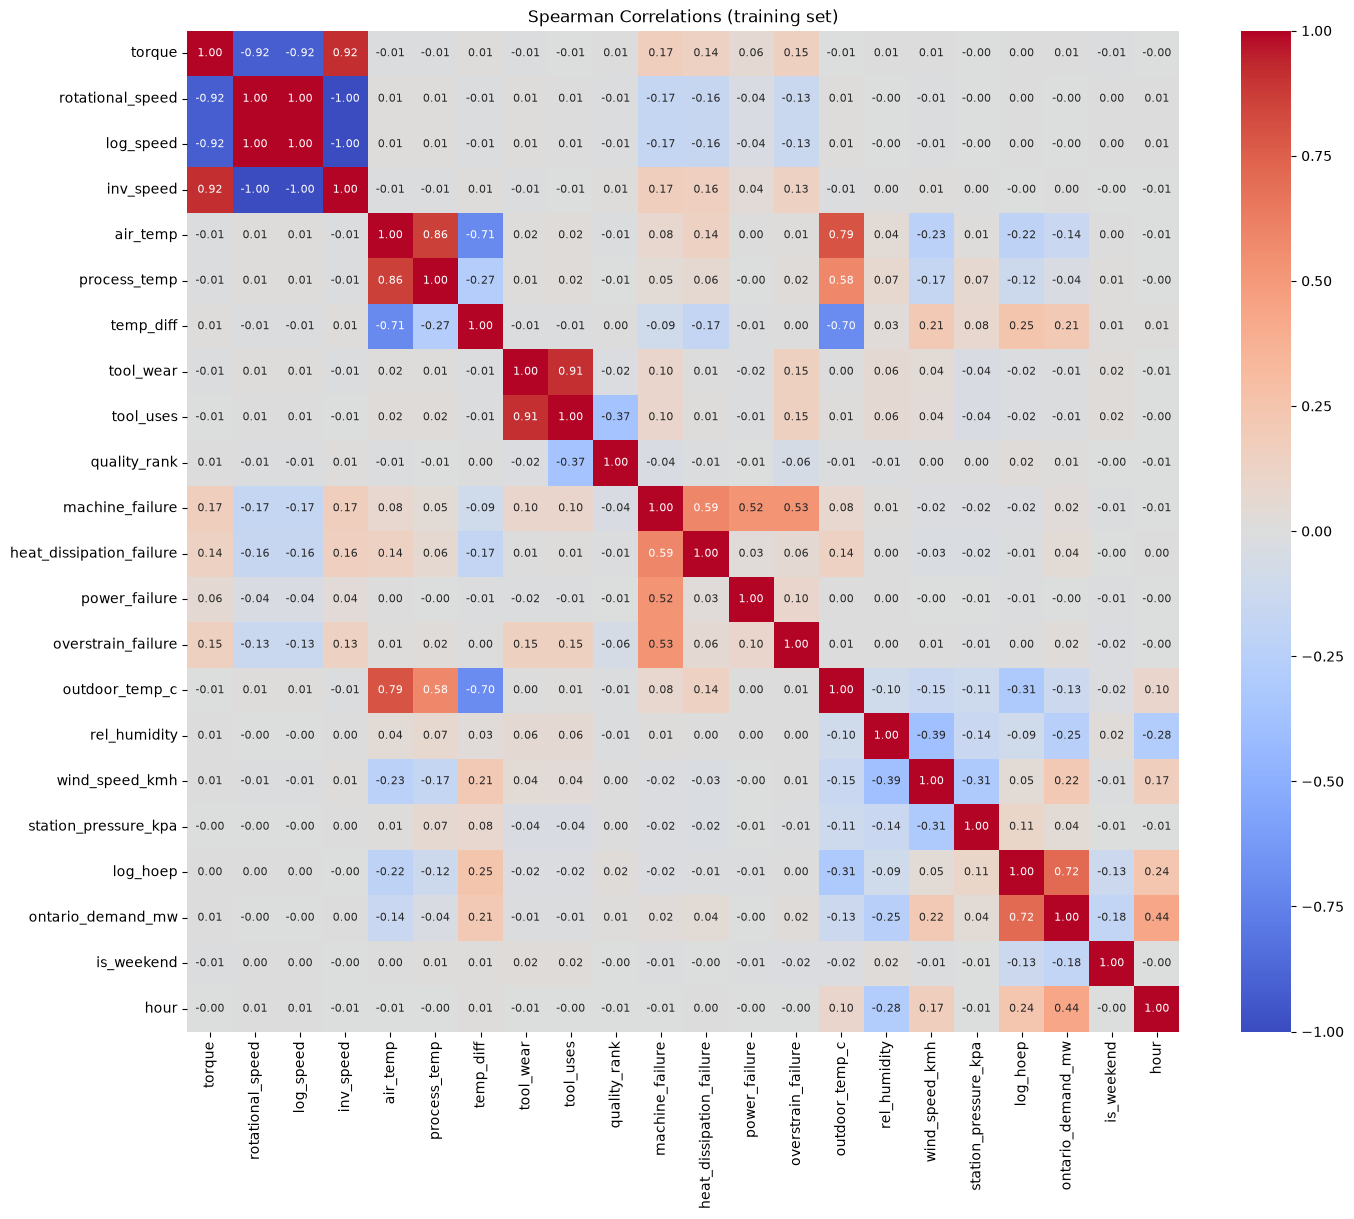

Correlation with torque (sorted):
rotational_speed           -0.916
log_speed                  -0.916
inv_speed                   0.916
machine_failure             0.171
overstrain_failure          0.153
heat_dissipation_failure    0.143
power_failure               0.059
air_temp                   -0.014
process_temp               -0.012
temp_diff                   0.012
is_weekend                 -0.010
tool_wear                  -0.008
ontario_demand_mw           0.007
outdoor_temp_c             -0.007
rel_humidity                0.007
wind_speed_kmh              0.007
tool_uses                  -0.005
quality_rank                0.005
log_hoep                    0.005
station_pressure_kpa       -0.002
hour                       -0.001
Name: torque, dtype: float64


In [20]:
corr_cols = ["torque", "rotational_speed", "log_speed", "inv_speed", "air_temp", "process_temp",
             "temp_diff", "tool_wear", "tool_uses", "quality_rank", "machine_failure",
             "heat_dissipation_failure", "power_failure", "overstrain_failure",
             "outdoor_temp_c", "rel_humidity", "wind_speed_kmh", "station_pressure_kpa",
             "log_hoep", "ontario_demand_mw", "is_weekend", "hour"]

corr_matrix = train[corr_cols].corr(method="spearman")

plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", annot_kws={"size": 8})
plt.title("Spearman Correlations (training set)")
plt.show()

print("Correlation with torque (sorted):")
print(corr_matrix["torque"].drop("torque").sort_values(key=abs, ascending=False).round(3))

**What the correlations tell us:**

- **Speed is by far the strongest predictor of torque** (Spearman ≈ **−0.92**, a strong relationship). The original, log and
  reciprocal versions all have the same Spearman value, because Spearman uses *ranks*, and the transformations keep the same order.
  (The ordinary Pearson correlation is −0.875 for the original speed and +0.915 for `inv_speed`, which shows the transformation helps
  a *linear* model.)
- The **failure flags** have weak positive correlations with torque (0.06 to 0.17). Failed runs, especially overstrain, have higher torque.
- **Temperatures, tool wear, tool uses and quality** have almost **no** correlation with torque (all below 0.02).
- **None of the new external variables** (outdoor temperature, humidity, wind, pressure, electricity price, Ontario demand, weekend,
  hour) are related to torque. All their correlations are below 0.011. This is what we expected after the sanity check: the outside
  conditions don't drive the machine readings in this data.
- In the full heatmap, `air_temp` and `outdoor_temp_c` correlate with each other (because of the shared summer hump), and so do the
  weather variables (temperature and dew point). That is another reason to expect collinearity in the full model.
- **Warning for MLR:** `rotational_speed`, `log_speed` and `inv_speed` are almost perfectly correlated with each other (≈ 1.00).
  Putting all three in one model will cause **collinearity**, which the lecture lists as a reason to choose variables carefully.

## 8. Simple Linear Regression (two models)

We build two SLR models, each with **one** independent variable, and compare them.

- **Model A: torque ~ rotational_speed** – the original speed reading.
- **Model B: torque ~ inv_speed** – our transformed variable (1000 ÷ speed).

We picked these two because speed is by far the strongest predictor of torque, and we want to test whether our Tukey's ladder
transformation actually gives a better model than the raw reading.

For each model we check (as in the lecture):

1. **F-statistic and its p-value** – does the model explain anything at all?
2. **R² / Adjusted R²** – how much of the variation in torque is explained?
3. **t-test p-value of the coefficient** – is the slope different from 0?
4. **Coefficient** – does the sign and size make sense?
5. **RMSE on the training and the test set** – how far off are the predictions, and does it hold up on new data?
6. **Residual plots** – are the regression assumptions OK?

### Model A: torque ~ rotational_speed

In [21]:
slr_a = smf.ols("torque ~ rotational_speed", data=train).fit()

print(slr_a.summary())

pred_train = slr_a.predict(train)
RMSE_trn_a = np.sqrt(mean_squared_error(train["torque"], pred_train))

pred_test = slr_a.predict(test)
RMSE_tst_a = np.sqrt(mean_squared_error(test["torque"], pred_test))

print(f"Train RMSE (Model A): {RMSE_trn_a:.2f}")
print(f"Test RMSE (Model A): {RMSE_tst_a:.2f}")

                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.765
Model:                            OLS   Adj. R-squared:                  0.765
Method:                 Least Squares   F-statistic:                 2.598e+04
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:52:20   Log-Likelihood:                -23959.
No. Observations:                8000   AIC:                         4.792e+04
Df Residuals:                    7998   BIC:                         4.794e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          115.0653      0.468  

### Model B: torque ~ inv_speed

In [22]:
slr_b = smf.ols("torque ~ inv_speed", data=train).fit()

print(slr_b.summary())

pred_train = slr_b.predict(train)
RMSE_trn_b = np.sqrt(mean_squared_error(train["torque"], pred_train))

pred_test = slr_b.predict(test)
RMSE_tst_b = np.sqrt(mean_squared_error(test["torque"], pred_test))

print(f"Train RMSE (Model B): {RMSE_trn_b:.2f}")
print(f"Test RMSE (Model B): {RMSE_tst_b:.2f}")

                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.837
Model:                            OLS   Adj. R-squared:                  0.837
Method:                 Least Squares   F-statistic:                 4.103e+04
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:52:20   Log-Likelihood:                -22492.
No. Observations:                8000   AIC:                         4.499e+04
Df Residuals:                    7998   BIC:                         4.500e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -50.4129      0.449   -112.276      0.0

### Fitted lines and residual plots

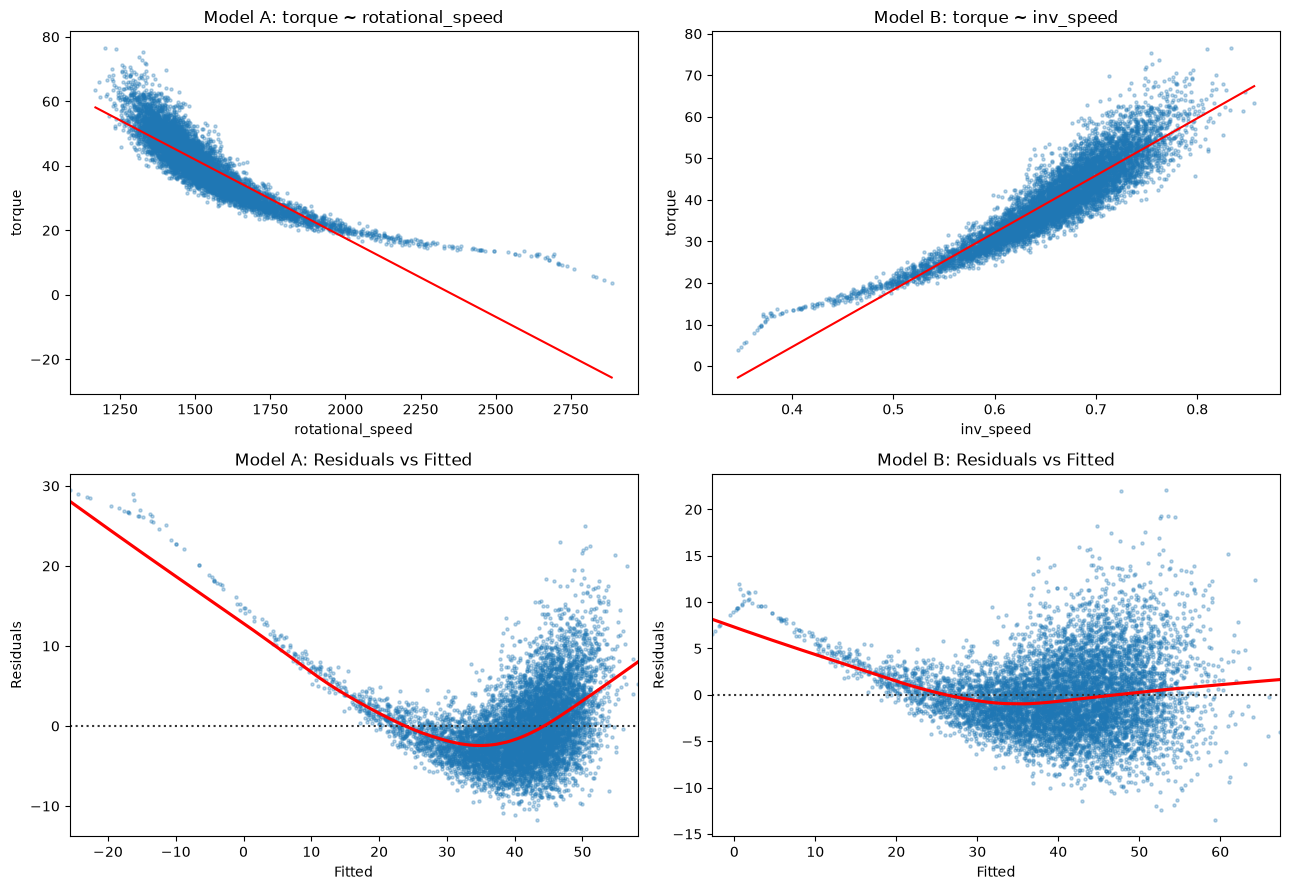

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Model A: fitted line
axes[0, 0].scatter(train["rotational_speed"], train["torque"], s=5, alpha=0.3)
x_line = np.linspace(train["rotational_speed"].min(), train["rotational_speed"].max(), 100)
axes[0, 0].plot(x_line, slr_a.predict(pd.DataFrame({"rotational_speed": x_line})), color="red")
axes[0, 0].set_title("Model A: torque ~ rotational_speed")
axes[0, 0].set_xlabel("rotational_speed")
axes[0, 0].set_ylabel("torque")

# Model B: fitted line
axes[0, 1].scatter(train["inv_speed"], train["torque"], s=5, alpha=0.3)
x_line = np.linspace(train["inv_speed"].min(), train["inv_speed"].max(), 100)
axes[0, 1].plot(x_line, slr_b.predict(pd.DataFrame({"inv_speed": x_line})), color="red")
axes[0, 1].set_title("Model B: torque ~ inv_speed")
axes[0, 1].set_xlabel("inv_speed")
axes[0, 1].set_ylabel("torque")

# Residuals vs Fitted (same as the demo)
sns.residplot(x=slr_a.fittedvalues, y=slr_a.resid, lowess=True,
              scatter_kws={"s": 5, "alpha": 0.3}, line_kws={"color": "red"}, ax=axes[1, 0])
axes[1, 0].set_title("Model A: Residuals vs Fitted")
axes[1, 0].set_xlabel("Fitted")
axes[1, 0].set_ylabel("Residuals")

sns.residplot(x=slr_b.fittedvalues, y=slr_b.resid, lowess=True,
              scatter_kws={"s": 5, "alpha": 0.3}, line_kws={"color": "red"}, ax=axes[1, 1])
axes[1, 1].set_title("Model B: Residuals vs Fitted")
axes[1, 1].set_xlabel("Fitted")
axes[1, 1].set_ylabel("Residuals")

plt.tight_layout()
plt.show()

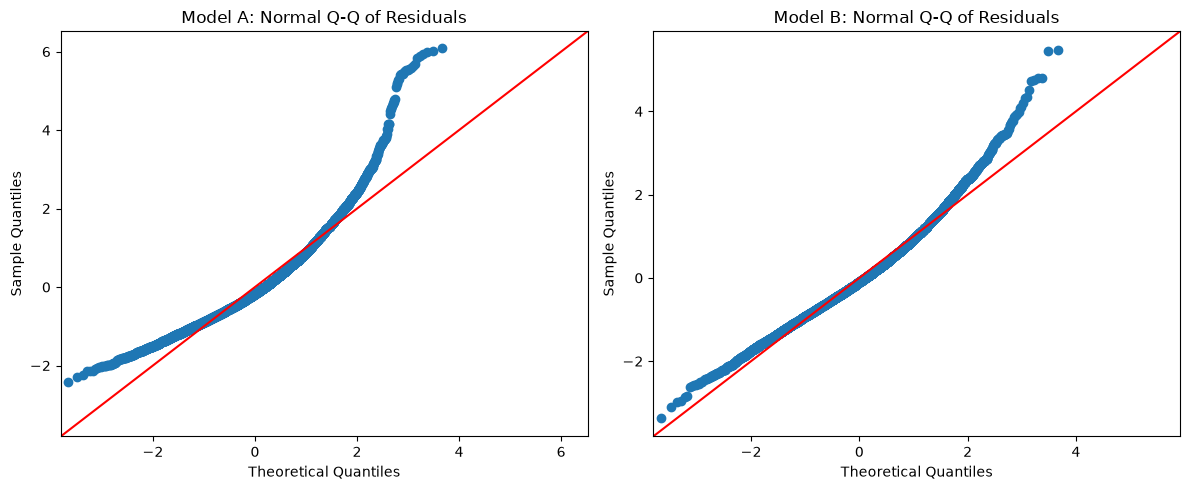

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sm.qqplot(slr_a.resid, line='45', fit=True, ax=axes[0])
axes[0].set_title("Model A: Normal Q-Q of Residuals")

sm.qqplot(slr_b.resid, line='45', fit=True, ax=axes[1])
axes[1].set_title("Model B: Normal Q-Q of Residuals")

plt.tight_layout()
plt.show()

### Compare the two SLR models

In [25]:
slr_compare = pd.DataFrame({
    "Model": ["A: rotational_speed", "B: inv_speed"],
    "F-stat": [slr_a.fvalue, slr_b.fvalue],
    "p-value (F)": [slr_a.f_pvalue, slr_b.f_pvalue],
    "R2": [slr_a.rsquared, slr_b.rsquared],
    "Adj R2": [slr_a.rsquared_adj, slr_b.rsquared_adj],
    "Coefficient": [slr_a.params["rotational_speed"], slr_b.params["inv_speed"]],
    "AIC": [slr_a.aic, slr_b.aic],
    "Train RMSE": [RMSE_trn_a, RMSE_trn_b],
    "Test RMSE": [RMSE_tst_a, RMSE_tst_b]
})

slr_compare.round(3)

,Model,F-stat,p-value (F),R2,Adj R2,Coefficient,AIC,Train RMSE,Test RMSE
0,A: rotational_speed,25981.242,0.000,0.765,0.765,-0.049,47921.162,4.835,4.789
1,B: inv_speed,41026.179,0.000,0.837,0.837,137.577,44988.651,4.025,4.013


### Which SLR model is better? **Model B (inv_speed) is clearly superior.**

| Measure | Model A: rotational_speed | Model B: inv_speed | Better |
|---|---|---|---|
| F-statistic (p-value) | 25,981 (p ≈ 0) | **41,026** (p ≈ 0) | B |
| R² / Adjusted R² | 0.765 | **0.837** | B |
| Train RMSE | 4.84 Nm | **4.03 Nm** | B |
| Test RMSE | 4.79 Nm | **4.01 Nm** | B |
| AIC (lower is better) | 47,921 | **44,989** | B |
| Residual skew / kurtosis | 1.31 / 6.54 | **0.66 / 4.16** | B |

**Walking through the evidence:**

1. **Both models are useful.** Both F-statistics have p-values of about 0, and both slopes have t-test p-values of about 0, so both
   speed variables really do explain torque.
2. **Model B explains more.** It explains **83.7%** of the variation in torque, compared with **76.5%** for Model A, a gain of about
   7 percentage points from the transformation alone.
3. **Model B's predictions are closer.** On average Model B is off by about **4.0 Nm**, compared with **4.8 Nm** for Model A, about 17% less error.
4. **Both models hold up on new data.** Train and test RMSE are almost the same for each model (A: 4.84 vs 4.79, B: 4.03 vs 4.01). So
   neither model is overfitting, and the improvement of B is real, not luck in the training data.
5. **The coefficients make sense.**
   - Model A: each extra 100 rpm lowers torque by about **4.9 Nm**. The sign is right (faster = less torque), but a straight line
     can't follow the curve. At 2,800 rpm Model A predicts **−21.6 Nm**, which is impossible, while the real torque there is about 4–6 Nm.
   - Model B: torque = −50.4 + 137.6 × (1000 ÷ rpm). At 1,400 rpm it predicts about 47.9 Nm and at 2,000 rpm about 18.4 Nm,
     both close to the data. At 2,800 rpm it predicts about −1.3 Nm. That is still a little too low, but much closer than Model A.
6. **Model B meets the assumptions better.**
   - *Residuals vs Fitted:* Model A shows a strong **U-shape**, so it is missing the curve (the linearity assumption is broken). Model B's red
     line is much flatter. It only bends at the far left, for the few very-high-speed runs.
   - *Q-Q plot:* Model A's residuals bend far away from the line in the upper tail (skew 1.31, kurtosis 6.5). Model B's residuals stay
     much closer to the line (skew 0.66, kurtosis 4.2), so they are closer to normal.
   - *Durbin-Watson* is about 2.0 for both, so there is no autocorrelation.
7. **Note:** Model A's summary warns about a large condition number (1.34e+04). With only one variable this is not
   multicollinearity. It happens because speed values are large (around 1,500), and it goes away in Model B (21.6).

**Conclusion:** Model B is better on **every** measure. Our Tukey's-ladder transformation (based on the physics: torque = power ÷ speed)
turned a curved relationship into a straight one, which is exactly what linear regression needs.

## 9. Multiple Linear Regression

### Step 1: Full model with all independent variables

We start with **every independent variable that can be used**. A few variables have to be left out, otherwise the model cannot
be calculated properly or it would be cheating:

| Left out | Reason |
|---|---|
| `power_w`, `power_margin_w`, `strain_minNm`, `osf_margin_minNm`, `energy_kwh`, `energy_cost_cad`, `operating_zone` | **Data leakage** – they are calculated from torque |
| `temp_diff` | Exactly process_temp − air_temp, so it is a perfect copy of two variables already in the model |
| `quality_label`, `quality_rank`, `tool_wear_added_min`, `osf_threshold_minNm` | One fixed value per product type, so they are perfect copies of `type` |
| `n_failure_modes`, `failure_type` | Built directly from the five failure flags, which are already in the model |
| `hour`, `day_of_week`, `month` | We use the simpler `shift`, `is_weekend` and `season` instead (24 hours or 12 months as straight-line numbers would not make sense) |
| `hoep_price` | We use the transformed `log_hoep` instead (less skewed) |
| `timestamp` | Only a key for joining the data |

That leaves **26 independent variables** for the full model.

In [26]:
predictors = [
    "type", "air_temp", "process_temp",
    "rotational_speed", "log_speed", "inv_speed",
    "tool_wear", "tool_uses", "wear_stage",
    "machine_failure", "tool_wear_failure", "heat_dissipation_failure",
    "power_failure", "overstrain_failure", "random_failure",
    "shift", "is_weekend", "season",
    "outdoor_temp_c", "dew_point_c", "rel_humidity", "precip_mm", "wind_speed_kmh", "station_pressure_kpa",
    "log_hoep", "ontario_demand_mw"
]

full_formula = "torque ~ " + " + ".join(predictors)
print(full_formula)

full_model = smf.ols(full_formula, data=train).fit()

print(full_model.summary())

pred_train = full_model.predict(train)
RMSE_trn_full = np.sqrt(mean_squared_error(train["torque"], pred_train))

pred_test = full_model.predict(test)
RMSE_tst_full = np.sqrt(mean_squared_error(test["torque"], pred_test))

print(f"Train RMSE (Full Model): {RMSE_trn_full:.2f}")
print(f"Test RMSE (Full Model): {RMSE_tst_full:.2f}")

torque ~ type + air_temp + process_temp + rotational_speed + log_speed + inv_speed + tool_wear + tool_uses + wear_stage + machine_failure + tool_wear_failure + heat_dissipation_failure + power_failure + overstrain_failure + random_failure + shift + is_weekend + season + outdoor_temp_c + dew_point_c + rel_humidity + precip_mm + wind_speed_kmh + station_pressure_kpa + log_hoep + ontario_demand_mw
                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.859
Model:                            OLS   Adj. R-squared:                  0.858
Method:                 Least Squares   F-statistic:                     1513.
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:52:22   Log-Likelihood:                -21918.
No. Observations:                8000   AIC:                         4.390e+04
Df Residuals:                    7967   BIC:     

**Full model results:**

- **F-statistic = 1,513 (p ≈ 0):** the model as a whole is useful.
- **R² = 0.859, Adjusted R² = 0.858:** a small improvement over SLR Model B (0.837). It uses 26 variables (32 terms, because
  categorical variables become several dummy terms).
- **Train RMSE = 3.75 Nm, Test RMSE = 3.72 Nm:** better than Model B (4.01), and train ≈ test, so there is no overfitting.

**Most variables are not significant (p > 0.05):**

- **All 11 variables from the external weather/electricity data:** `shift`, `is_weekend`, `season`, `outdoor_temp_c`, `dew_point_c`,
  `rel_humidity`, `precip_mm`, `wind_speed_kmh`, `station_pressure_kpa`, `log_hoep` and `ontario_demand_mw` (p-values from 0.17 to 0.96).
- From the machine data: `type`, `air_temp`, `process_temp`, `tool_wear`, `tool_uses`, `machine_failure`, `tool_wear_failure`,
  `heat_dissipation_failure` and `random_failure`.
- `wear_stage` is borderline (two levels at p ≈ 0.04–0.05).

**Significant variables:** the three speed variables, `power_failure` (+10.2 Nm) and `overstrain_failure` (+5.4 Nm).

**Problem – collinearity:** the summary warns about a very large condition number (about 1.6e+08). This is caused by having
`rotational_speed`, `log_speed` and `inv_speed` together. You can see it in the coefficients: `log_speed` has a **positive** coefficient
(+189), even though torque goes **down** as speed goes up. On its own that sign does not make sense. The three speed variables are
"fighting" each other, so we can't trust their individual coefficients.

### Step 2: Backward Selection

We use the same `backward_selection` function as shown in class. It starts with all the variables, removes the one with the
**highest p-value**, refits the model, and repeats until every variable left has a p-value of **0.05 or lower**.

The only change: we give it just the torque column and our predictor list (instead of the whole data frame), so that it does not
pick up the leaky or duplicate variables.

In [27]:
def backward_selection(data, response):

    predictors = [col for col in data.columns if col != response]

    while True:

        formula = response + " ~ " + " + ".join(predictors)

        model = smf.ols(formula, data=data).fit()

        # Get largest p-value excluding intercept
        pvals = model.pvalues.drop("Intercept")

        worst_p = pvals.max()

        if worst_p <= 0.05:
            break

        worst_term = pvals.idxmax()

        # Handle categorical dummy variables
        base_var = worst_term.split("[")[0]

        if base_var in predictors:
            print(f"Removing: {base_var}  (p = {worst_p:.4f})")
            predictors.remove(base_var)
        else:
            print(f"Skipping term: {worst_term}")
            break

    return model

back_model = backward_selection(train[["torque"] + predictors], "torque")

print(back_model.summary())

pred_train = back_model.predict(train)
RMSE_trn_bck = np.sqrt(mean_squared_error(train["torque"], pred_train))

pred_test = back_model.predict(test)
RMSE_tst_bck = np.sqrt(mean_squared_error(test["torque"], pred_test))

print(f"Train RMSE (Backward Model): {RMSE_trn_bck:.2f}")
print(f"Test RMSE (Backward Model): {RMSE_tst_bck:.2f}")

Removing: dew_point_c  (p = 0.9645)
Removing: process_temp  (p = 0.8677)
Removing: air_temp  (p = 0.9513)
Removing: type  (p = 0.8509)
Removing: tool_uses  (p = 0.8346)
Removing: machine_failure  (p = 0.8202)
Removing: station_pressure_kpa  (p = 0.7261)
Removing: log_hoep  (p = 0.6808)
Removing: season  (p = 0.5771)
Removing: wind_speed_kmh  (p = 0.4932)
Removing: precip_mm  (p = 0.5203)
Removing: wear_stage  (p = 0.4300)
Removing: is_weekend  (p = 0.4486)
Removing: outdoor_temp_c  (p = 0.3207)
Removing: rel_humidity  (p = 0.3081)
Removing: heat_dissipation_failure  (p = 0.3058)
Removing: ontario_demand_mw  (p = 0.3035)
Removing: random_failure  (p = 0.2478)
Removing: shift  (p = 0.2134)
Removing: tool_wear  (p = 0.1768)
                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.858
Model:                            OLS   Adj. R-squared:                  0.858
Method:                 Least Sq

**Backward selection results:**

- It removed **20 variables**, one at a time, starting with `dew_point_c` (p = 0.96) and ending with `tool_wear` (p = 0.18).
  **All 11 external variables were removed**, as were type, both temperatures, tool wear, tool uses, wear stage and three failure flags.
- It kept **6 variables:** `rotational_speed`, `log_speed`, `inv_speed`, `tool_wear_failure`, `power_failure`, `overstrain_failure`.
- **R² = 0.858, Adjusted R² = 0.858, F = 8,065, AIC = 43,875 (the lowest of all models).**
- **Train RMSE = 3.75, Test RMSE = 3.72:** the same as the full model, with 26 fewer terms. Removing those variables cost us nothing.

**Remaining concerns:**

- The **collinearity problem is still there** (condition number 1.4e+07), because all three speed variables survived. Their coefficients
  (−0.037, +187, +341) are hard to explain.
- `tool_wear_failure` is only just significant (p = 0.016) and is based on only 35 tool wear failures in the training set.

The lecture says automatic selection should be used "as a guide only", so next we try simpler models by hand.

### Step 3: Experiment with Variable Combinations

We also try simpler models by hand and see if we lose anything:

- **Simplified model:** `inv_speed` (our best single variable) plus the two failure flags with the biggest, clearest effects in
  the backward model (`power_failure` and `overstrain_failure`). This removes the three overlapping speed variables.
- **Sensor-only model:** `inv_speed` and `rotational_speed` only, with no failure information. This is the most practical model
  for live use, because failure flags are only known *after* a run ends, but speed is known while the machine is running.

In [28]:
exp1_formula = "torque ~ inv_speed + power_failure + overstrain_failure"
exp1_model = smf.ols(exp1_formula, data=train).fit()

print(exp1_model.summary())

pred_train = exp1_model.predict(train)
RMSE_trn_exp1 = np.sqrt(mean_squared_error(train["torque"], pred_train))

pred_test = exp1_model.predict(test)
RMSE_tst_exp1 = np.sqrt(mean_squared_error(test["torque"], pred_test))

print(f"Train RMSE (Simplified Model): {RMSE_trn_exp1:.2f}")
print(f"Test RMSE (Simplified Model): {RMSE_tst_exp1:.2f}")

                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.855
Model:                            OLS   Adj. R-squared:                  0.855
Method:                 Least Squares   F-statistic:                 1.569e+04
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:52:22   Log-Likelihood:                -22028.
No. Observations:                8000   AIC:                         4.406e+04
Df Residuals:                    7996   BIC:                         4.409e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            -50.3521      0

In [29]:
exp2_model = smf.ols("torque ~ inv_speed + rotational_speed", data=train).fit()

print(exp2_model.summary())

pred_train = exp2_model.predict(train)
RMSE_trn_exp2 = np.sqrt(mean_squared_error(train["torque"], pred_train))

pred_test = exp2_model.predict(test)
RMSE_tst_exp2 = np.sqrt(mean_squared_error(test["torque"], pred_test))

print(f"Train RMSE (Sensor-only Model): {RMSE_trn_exp2:.2f}")
print(f"Test RMSE (Sensor-only Model): {RMSE_tst_exp2:.2f}")

                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.848
Model:                            OLS   Adj. R-squared:                  0.847
Method:                 Least Squares   F-statistic:                 2.223e+04
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:52:22   Log-Likelihood:                -22222.
No. Observations:                8000   AIC:                         4.445e+04
Df Residuals:                    7997   BIC:                         4.447e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         -142.7826      3.928  

### Step 4: Compare all Models

In [30]:
models = {
    "SLR A (rotational_speed)": (slr_a, RMSE_trn_a, RMSE_tst_a),
    "SLR B (inv_speed)": (slr_b, RMSE_trn_b, RMSE_tst_b),
    "Full": (full_model, RMSE_trn_full, RMSE_tst_full),
    "Backward": (back_model, RMSE_trn_bck, RMSE_tst_bck),
    "Simplified": (exp1_model, RMSE_trn_exp1, RMSE_tst_exp1),
    "Sensor-only": (exp2_model, RMSE_trn_exp2, RMSE_tst_exp2)
}

comparison = pd.DataFrame({
    "Model": list(models.keys()),
    "No. of terms": [m.df_model for m, _, _ in models.values()],
    "F-stat": [m.fvalue for m, _, _ in models.values()],
    "R2": [m.rsquared for m, _, _ in models.values()],
    "Adj R2": [m.rsquared_adj for m, _, _ in models.values()],
    "AIC": [m.aic for m, _, _ in models.values()],
    "Condition No.": [m.condition_number for m, _, _ in models.values()],
    "Train RMSE": [trn for _, trn, _ in models.values()],
    "Test RMSE": [tst for _, _, tst in models.values()]
})

comparison.round(3)

,Model,No. of terms,F-stat,R2,Adj R2,AIC,Condition No.,Train RMSE,Test RMSE
0,SLR A (rotational_speed),1.000,25981.242,0.765,0.765,47921.162,13413.755,4.835,4.789
1,SLR B (inv_speed),1.000,41026.179,0.837,0.837,44988.651,21.639,4.025,4.013
2,Full,32.000,1512.848,0.859,0.858,43901.441,155526549.215,3.746,3.724
3,Backward,6.000,8065.347,0.858,0.858,43874.520,14412755.846,3.752,3.722
4,Simplified,3.000,15685.091,0.855,0.855,44063.039,21.955,3.798,3.768
5,Sensor-only,2.000,22225.969,0.848,0.847,44449.439,180437.544,3.891,3.880


### Step 5: Check Assumptions of the Final Model

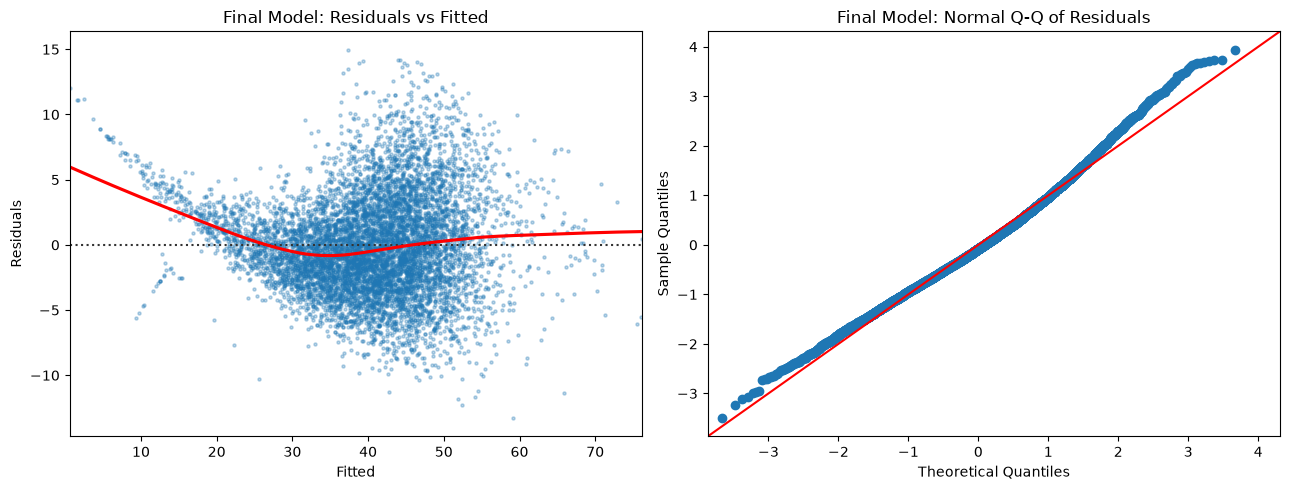

In [31]:
final_model = exp1_model

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.residplot(x=final_model.fittedvalues, y=final_model.resid, lowess=True,
              scatter_kws={"s": 5, "alpha": 0.3}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_xlabel("Fitted")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Final Model: Residuals vs Fitted")

sm.qqplot(final_model.resid, line='45', fit=True, ax=axes[1])
axes[1].set_title("Final Model: Normal Q-Q of Residuals")

plt.tight_layout()
plt.show()

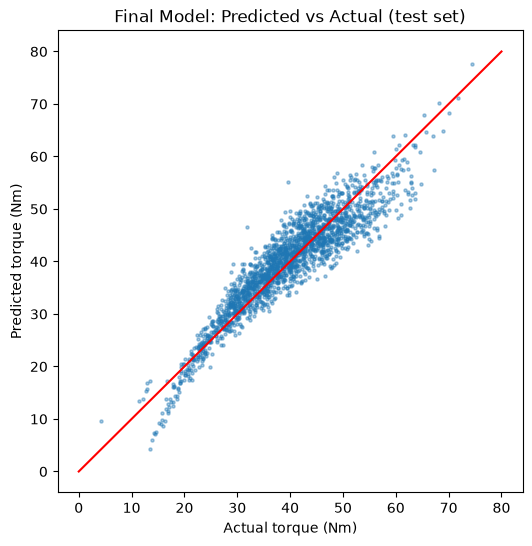

In [32]:
# Predicted vs actual torque on the TEST set
pred_test_final = final_model.predict(test)

plt.figure(figsize=(6, 6))
plt.scatter(test["torque"], pred_test_final, s=5, alpha=0.4)
plt.plot([0, 80], [0, 80], color="red")
plt.xlabel("Actual torque (Nm)")
plt.ylabel("Predicted torque (Nm)")
plt.title("Final Model: Predicted vs Actual (test set)")
plt.show()

### Our final model: torque ~ inv_speed + power_failure + overstrain_failure

**Evidence for choosing it:**

| Measure | Backward (6 variables) | **Final (3 variables)** |
|---|---|---|
| F-statistic | 8,065 | **15,685** |
| R² / Adjusted R² | 0.858 | 0.855 |
| AIC | 43,875 | 44,063 |
| Condition number | 14,400,000 | **22** |
| Train RMSE | 3.75 Nm | 3.80 Nm |
| Test RMSE | 3.72 Nm | 3.77 Nm |

1. **Almost the same accuracy with half the variables.** R² is only 0.003 lower, and test RMSE is only **0.05 Nm** worse. That is tiny next
   to torque's standard deviation of about 10 Nm. The lecture's Occam's Razor principle says the smallest model that fits the data is best.
2. **No collinearity.** The condition number drops from about 14 million to **22**, so every coefficient can be trusted and explained.
3. **Every variable is highly significant** (all p-values < 0.001), and the F-statistic is the highest of all the multi-variable models.
4. **The coefficients make sense:**
   - `inv_speed` (+137.2): the same physics as SLR Model B. Slower spindle = higher torque.
   - `overstrain_failure` (+5.4 Nm): overstrained runs carry about 5 Nm more torque than their speed would suggest. This matches the
     failure rule (tool wear × torque too high) and our Workshop A finding that failed runs have higher torque.
   - `power_failure` (+12.2 Nm): power failures happen at the **extreme ends** of the speed range, where the speed curve alone
     under-predicts torque (see the left side of the residual plot). This flag corrects for that.
5. **No overfitting:** train RMSE (3.80) and test RMSE (3.77) are almost identical.
6. **Compared with our best SLR (Model B):** R² goes from 0.837 to **0.855**, and test RMSE goes from 4.01 to **3.77 Nm** (about 6% less error).

**Assumption checks:**

- *Residuals vs Fitted:* the red line is close to flat for most of the data (fitted values from about 20 to 75 Nm). There is still a small
  upward bend at the far left (the few very-high-speed, low-torque runs), and the spread is a little wider in the middle. So the
  assumptions are mostly, but not perfectly, met.
- *Q-Q plot:* the residuals follow the line well, with a slightly heavier upper tail (skew 0.42). This is much better than SLR Model A.
- *Predicted vs Actual (test set):* the points sit close to the red line across the whole range.

**One limitation to keep in mind:** the failure flags are only known **after** a run ends. If the goal is to predict torque **while** the
machine is running, the **sensor-only model** (`inv_speed + rotational_speed`, test RMSE 3.88 Nm, R² 0.848) is the best practical choice.
It is only slightly less accurate.

## 10. Final Summary

1. **Data:** we added the **product type specifications** and **failure rules** from the official documentation (which recreated the
   HDF, PWF and OSF flags exactly). We also merged three **separate public datasets** on an hourly timestamp: Environment Canada weather
   for Kitchener-Waterloo, and IESO electricity price and Ontario demand. Finally, we added our **Workshop B operating zones**.
   The study file now has **45 usable variables**, and all categorical variables are converted.
2. **Transformations:** Tukey's ladder (log and reciprocal) reduced the skew in rotational speed and electricity price, and
   missing weather hours were filled by interpolation. More importantly, `inv_speed`
   (1000 ÷ rpm) straightened out the curved relationship with torque, as the physics (torque = power ÷ speed) suggests.
3. **Split:** 80/20 train/test. The KS and chi-square tests showed the two sets are comparable. The small differences are a slightly
   higher failure rate in the test set (3.6% vs 3.3%) and the electricity price spikes falling mostly in the training set.
4. **SLR:** `inv_speed` beat `rotational_speed` on every measure: R² 0.837 vs 0.765, test RMSE 4.01 vs 4.79 Nm, and better residual plots.
5. **MLR:** the full model and backward selection reached R² ≈ 0.858, but kept three overlapping speed variables (strong collinearity).
   Our **final model, torque ~ inv_speed + power_failure + overstrain_failure**, has almost the same accuracy (R² 0.855, test RMSE
   3.77 Nm) with only 3 variables, no collinearity and coefficients that make sense.
6. **The external data did not help predict torque.** Backward selection removed all 11 weather/electricity variables. This makes
   sense, because the sanity check showed the AI4I data does not react to real outside conditions. The new variables are still useful
   for other questions in our term project, such as the energy cost of each run.
7. **What this means for our term project:** speed explains about 84% of the torque. Overstrain and power failures add extra torque that
   speed alone can't explain. A run whose real torque is well above what the model expects is a warning sign worth investigating.